# 03 — Double-Sérsic mock with CompositeModel

This notebook validates the first multi-component BayMorph workflow.

Workflow:

1. build a bulge component;
2. build a disk component;
3. combine them with `CompositeModel`;
4. recover the two component fluxes with `DynestyFitter`;
5. repeat the experiment with Gaussian noise and PSF convolution using `ConvolvedModel`.

The goal is architectural validation: `CompositeModel`, `ConvolvedModel`, `ParameterSet`, `DynestyFitter`, and `PosteriorResult` should work together without changing the fitting backend.

## Imports

In [1]:
import matplotlib.pyplot as plt

from baymorph import (
    CompositeModel,
    ConvolvedModel,
    DynestyFitter,
    GaussianPSF,
    Parameter,
    ParameterSet,
    SersicModel,
    add_gaussian_noise,
    make_constant_noise_map,
    plot_data_model_residual,
)

## True component parameters

In [2]:
true_flux_bulge = 3000.0
true_flux_disk = 7000.0

shared_geometry = {
    "q": 0.8,
    "theta": 0.0,
    "x0": 30.0,
    "y0": 30.0,
}

bulge_shape = {
    "re": 3.0,
    "n": 4.0,
}

disk_shape = {
    "re": 12.0,
    "n": 1.0,
}

## Build true CompositeModel

In [3]:
bulge = SersicModel(
    flux=true_flux_bulge,
    **bulge_shape,
    **shared_geometry,
)

disk = SersicModel(
    flux=true_flux_disk,
    **disk_shape,
    **shared_geometry,
)

true_model = CompositeModel(
    [
        bulge,
        disk,
    ]
)

## Render clean composite mock

In [4]:
data = true_model.render(
    shape=(60, 60),
)

noise = make_constant_noise_map(
    data.shape,
    sigma=1.0,
)

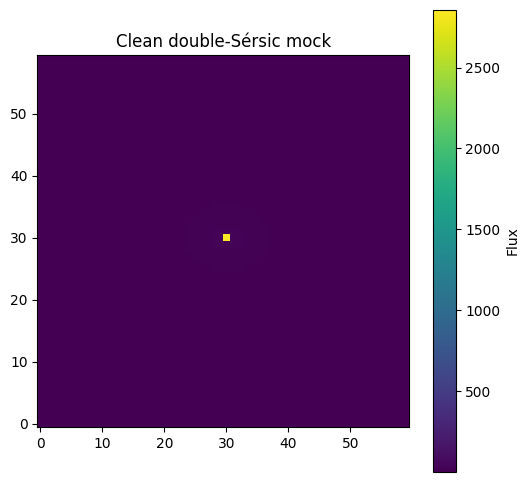

Total flux: 10000.000000000004
True bulge flux: 3000.0
True disk flux: 7000.0


In [5]:
plt.figure(figsize=(6, 6))
plt.imshow(
    data,
    origin="lower",
)
plt.colorbar(label="Flux")
plt.title("Clean double-Sérsic mock")
plt.show()

print("Total flux:", data.sum())
print("True bulge flux:", true_flux_bulge)
print("True disk flux:", true_flux_disk)

## Clean model factory

In [6]:
def model_factory(
    flux_bulge,
    flux_disk,
):
    bulge = SersicModel(
        flux=flux_bulge,
        **bulge_shape,
        **shared_geometry,
    )

    disk = SersicModel(
        flux=flux_disk,
        **disk_shape,
        **shared_geometry,
    )

    return CompositeModel(
        [
            bulge,
            disk,
        ]
    )

## Parameters

In [7]:
parameters = ParameterSet(
    [
        Parameter(
            "flux_bulge",
            500.0,
            6000.0,
        ),
        Parameter(
            "flux_disk",
            3000.0,
            12000.0,
        ),
    ]
)

## Fit clean mock

In [8]:
fitter = DynestyFitter(
    model_factory=model_factory,
    data=data,
    noise=noise,
    parameters=parameters,
)

result = fitter.run(
    nlive=100,
    sample="rwalk",
    print_progress=True,
)

iter: 1493 | +100 | bound: 11 | nc: 1 | ncall: 28089 | eff(%):  5.692 | loglstar:   -inf < -3308.180 <    inf | logz: -3320.768 +/-  0.340 | dlogz:  0.001 >  0.109                                   

## Clean recovery

In [9]:
best = result.best_parameters
best

{'flux_bulge': 2999.946159323104, 'flux_disk': 7001.05641364265}

In [10]:
print(result.summary("flux_bulge"))
print(result.summary("flux_disk"))

{'q16': 2998.95864696663, 'median': 2999.9035766919574, 'q84': 3000.9546954140496}
{'q16': 6970.081845621765, 'median': 6998.658851699115, 'q84': 7028.927317853727}


(<Figure size 1800x600 with 6 Axes>,
 array([<Axes: title={'center': 'Data'}>,
        <Axes: title={'center': 'Model'}>,
        <Axes: title={'center': 'Residual'}>], dtype=object))

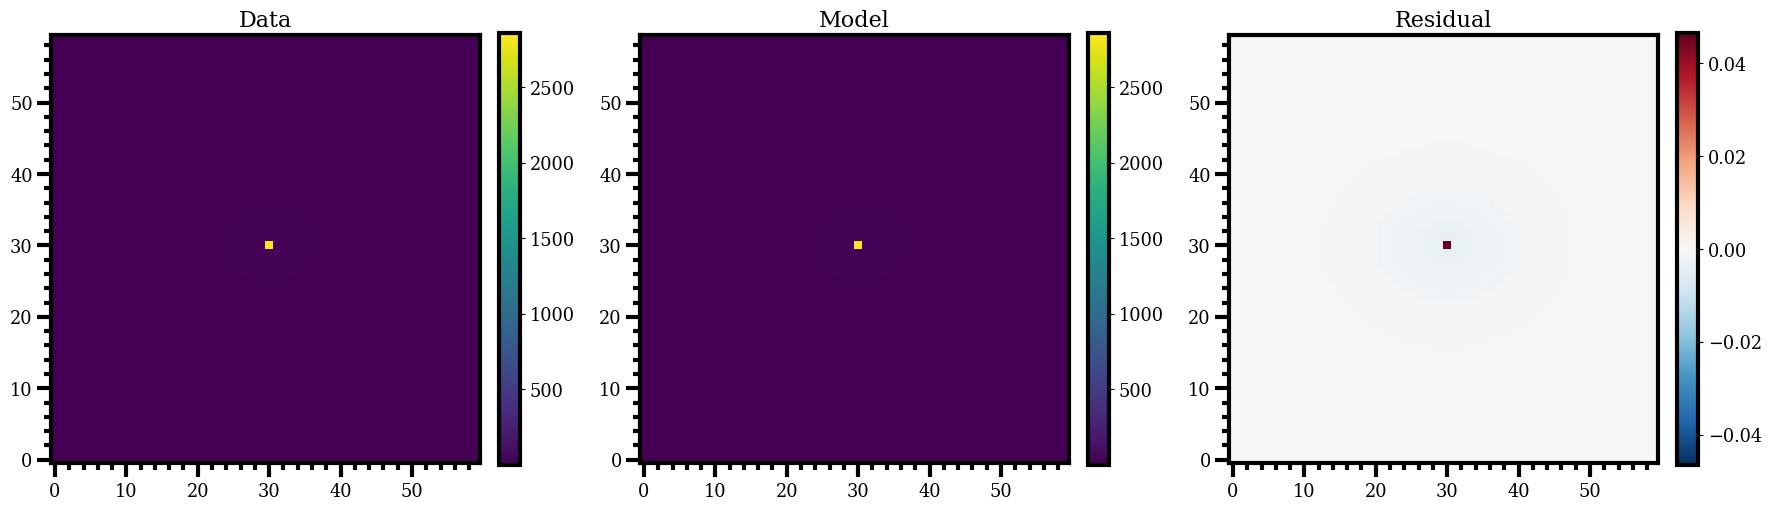

In [11]:
best_model = model_factory(
    flux_bulge=best["flux_bulge"],
    flux_disk=best["flux_disk"],
)

best_image = best_model.render(
    shape=data.shape,
)

plot_data_model_residual(
    data,
    best_image,
)

## Add PSF convolution and noise

In [12]:
psf = GaussianPSF(
    fwhm=3.0,
)

psf_true_model = ConvolvedModel(
    true_model,
    psf,
)

clean_psf_data = psf_true_model.render(
    shape=data.shape,
)

noisy_psf_data = add_gaussian_noise(
    clean_psf_data,
    sigma=1.0,
    seed=42,
)

noise_psf = make_constant_noise_map(
    noisy_psf_data.shape,
    sigma=1.0,
)

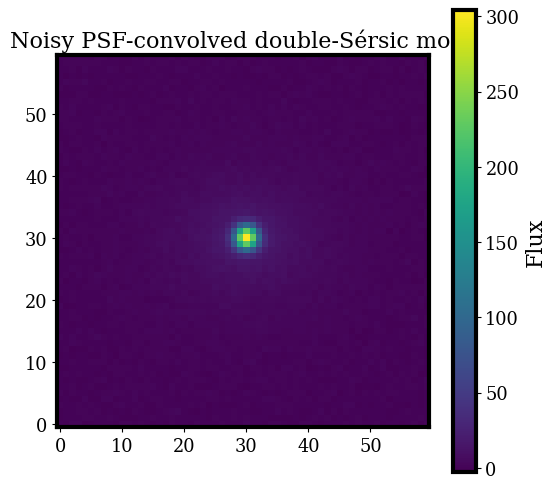

In [13]:
plt.figure(figsize=(6, 6))
plt.imshow(
    noisy_psf_data,
    origin="lower",
)
plt.colorbar(label="Flux")
plt.title("Noisy PSF-convolved double-Sérsic mock")
plt.show()

## PSF-convolved model factory

In [14]:
def psf_model_factory(
    flux_bulge,
    flux_disk,
):
    composite = model_factory(
        flux_bulge=flux_bulge,
        flux_disk=flux_disk,
    )

    return ConvolvedModel(
        composite,
        psf,
    )

## Fit noisy PSF-convolved mock

In [15]:
psf_fitter = DynestyFitter(
    model_factory=psf_model_factory,
    data=noisy_psf_data,
    noise=noise_psf,
    parameters=parameters,
)

psf_result = psf_fitter.run(
    nlive=150,
    sample="rwalk",
    print_progress=True,
)

iter: 1955 | +150 | bound: 10 | nc: 1 | ncall: 36601 | eff(%):  5.775 | loglstar:   -inf < -5108.241 <    inf | logz: -5119.318 +/-  0.259 | dlogz:  0.001 >  0.159                                   

## PSF recovery

In [16]:
psf_best = psf_result.best_parameters
psf_best

{'flux_bulge': 3005.7637514918015, 'flux_disk': 6931.796599063564}

In [17]:
print(psf_result.summary("flux_bulge"))
print(psf_result.summary("flux_disk"))

{'q16': 3000.651174221169, 'median': 3005.1929061077735, 'q84': 3010.6782408490953}
{'q16': 6895.704052422667, 'median': 6928.60397892398, 'q84': 6962.944179655463}


(<Figure size 1800x600 with 6 Axes>,
 array([<Axes: title={'center': 'Data'}>,
        <Axes: title={'center': 'Model'}>,
        <Axes: title={'center': 'Residual'}>], dtype=object))

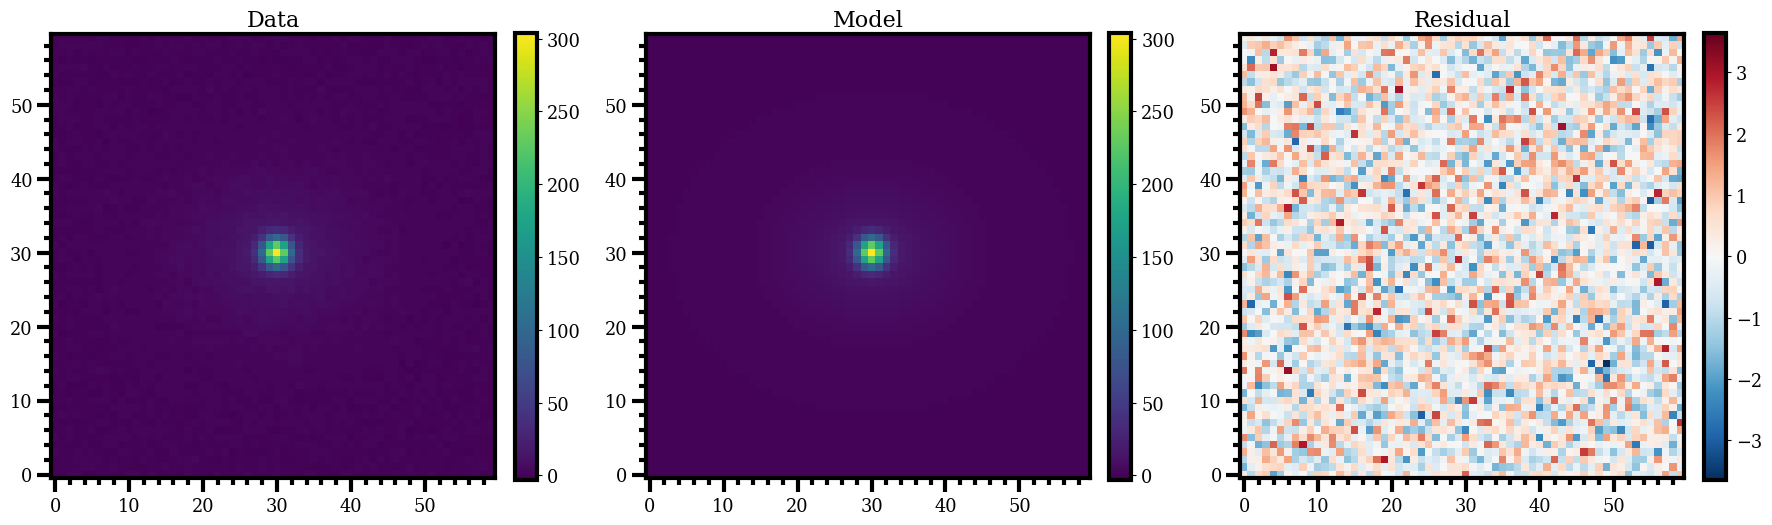

In [18]:
psf_best_model = psf_model_factory(
    flux_bulge=psf_best["flux_bulge"],
    flux_disk=psf_best["flux_disk"],
)

psf_best_image = psf_best_model.render(
    shape=noisy_psf_data.shape,
)

plot_data_model_residual(
    noisy_psf_data,
    psf_best_image,
)

## Quantitative recovery summary

In [19]:
recovered_flux_bulge = psf_best["flux_bulge"]
recovered_flux_disk = psf_best["flux_disk"]

bulge_error_percent = 100 * (
    recovered_flux_bulge - true_flux_bulge
) / true_flux_bulge

disk_error_percent = 100 * (
    recovered_flux_disk - true_flux_disk
) / true_flux_disk

summary = {
    "parameter": [
        "flux_bulge",
        "flux_disk",
    ],
    "true": [
        true_flux_bulge,
        true_flux_disk,
    ],
    "recovered": [
        recovered_flux_bulge,
        recovered_flux_disk,
    ],
    "error_percent": [
        bulge_error_percent,
        disk_error_percent,
    ],
}

summary

{'parameter': ['flux_bulge', 'flux_disk'],
 'true': [3000.0, 7000.0],
 'recovered': [3005.7637514918015, 6931.796599063564],
 'error_percent': [0.1921250497267162, -0.974334299091944]}

In [20]:
print("Notebook 03 conclusion:")
print("CompositeModel successfully represents a two-component Sérsic galaxy.")
print("DynestyFitter with ParameterSet recovers the two component fluxes.")
print("ConvolvedModel successfully applies PSF convolution to a CompositeModel.")
print("The noisy PSF-convolved residuals are dominated by injected Gaussian noise.")

Notebook 03 conclusion:
CompositeModel successfully represents a two-component Sérsic galaxy.
DynestyFitter with ParameterSet recovers the two component fluxes.
ConvolvedModel successfully applies PSF convolution to a CompositeModel.
The noisy PSF-convolved residuals are dominated by injected Gaussian noise.
